# 🔍 Deepfake Analysis: Data Cleaning & Inventory with Pandas
### College Project Demonstration — Notebook 01
**Author:** AI Project Team  
**Focus:** Reading Raw Directories, Metadata Ingestion, Identifying Corrupt Files, and Dataset Manifest Generation.


## 1. Setup & Environment
We import Pandas, NumPy, Matplotlib, and OS utilities to perform a structured audit of our multimodal dataset.


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

# Project base paths
PROJECT_ROOT = Path(r"D:\deepfake_college_project\Deepfake-Analysis")
DATASET_RAW = PROJECT_ROOT / "dataset" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
MANIFEST_PATH = REPORTS_DIR / "dataset_manifest.csv"
CORRUPT_LOG = REPORTS_DIR / "corrupted_files.txt"

print(f"Project Root: {PROJECT_ROOT}")
print(f"Raw Dataset Dir: {DATASET_RAW}")
print(f"Manifest Exists: {MANIFEST_PATH.exists()}")
print(f"Corrupted Files Log Exists: {CORRUPT_LOG.exists()}")


Project Root: D:\deepfake_college_project\Deepfake-Analysis
Raw Dataset Dir: D:\deepfake_college_project\Deepfake-Analysis\dataset\raw
Manifest Exists: True
Corrupted Files Log Exists: True


## 2. Ingesting Raw Dataset Directories & Structure
We inspect the file distribution across the three modalities: **Images**, **Videos**, and **Audio**.


In [2]:
# Scan files across raw directories
modalities = ["images", "videos", "audio"]
summary_data = []

for mod in modalities:
    folder = DATASET_RAW / mod
    if folder.exists():
        file_count = 0
        total_size = 0
        exts = {}
        for root, _, files in os.walk(folder):
            for f in files:
                file_count += 1
                fp = Path(root) / f
                try:
                    total_size += fp.stat().st_size
                except:
                    pass
                ext = fp.suffix.lower()
                exts[ext] = exts.get(ext, 0) + 1
        summary_data.append({
            "Modality": mod.capitalize(),
            "Total Files": file_count,
            "Total Size (GB)": round(total_size / (1024**3), 2),
            "Top Extensions": str(sorted(exts.items(), key=lambda x: x[1], reverse=True)[:3])
        })

df_raw_summary = pd.DataFrame(summary_data)
df_raw_summary


,Modality,Total Files,Total Size (GB),Top Extensions
0,Images,132587,7.93,"[('.png', 111026), ('.jpg', 21560), ('', 1)]"
1,Videos,24991,28.68,"[('.mp4', 24991)]"
2,Audio,4632,0.00,"[('.ini', 4130), ('.txt', 501), ('.csv', 1)]"


## 3. Metadata Ingestion: FakeAVCeleb Dataset
The multimodal **FakeAVCeleb** dataset comes with an official ground-truth `meta_data.csv`.  
Let's analyze it with Pandas to understand the exact generation methods, races, genders, and cross-modal tampering types.


In [3]:
meta_csv_path = DATASET_RAW / "audio" / "audio_dataset.zio" / "FakeAVCeleb_v1.2" / "FakeAVCeleb_v1.2" / "meta_data.csv"

if meta_csv_path.exists():
    df_meta = pd.read_csv(meta_csv_path)
    print("Shape:", df_meta.shape)
    display(df_meta.head(5))
else:
    print("FakeAVCeleb metadata not found at expected path.")


Shape: (21566, 10)


,source,target1,target2,method,category,type,race,gender,path,Unnamed: 9
0,id00076,-,-,real,A,RealVideo-RealAudio,African,men,00109.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
1,id00166,-,-,real,A,RealVideo-RealAudio,African,men,00010.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
2,id00173,-,-,real,A,RealVideo-RealAudio,African,men,00118.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
3,id00366,-,-,real,A,RealVideo-RealAudio,African,men,00118.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
4,id00391,-,-,real,A,RealVideo-RealAudio,African,men,00052.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...


### 3.1 Distribution of Deepfake Categories in Metadata
In FakeAVCeleb:
- `RealVideo-RealAudio`: Bonafide authentic media
- `FakeVideo-RealAudio`: Manipulated facial video (e.g. Faceswap/FSGAN) with authentic audio
- `RealVideo-FakeAudio`: Authentic facial video with cloned/synthesized voice (RTVC)
- `FakeVideo-FakeAudio`: Tampered video + tampered audio (Wav2Lip)


Cross-modal tampering breakdown:
type
FakeVideo-FakeAudio    10857
FakeVideo-RealAudio     9709
RealVideo-RealAudio      500
RealVideo-FakeAudio      500
Name: count, dtype: int64


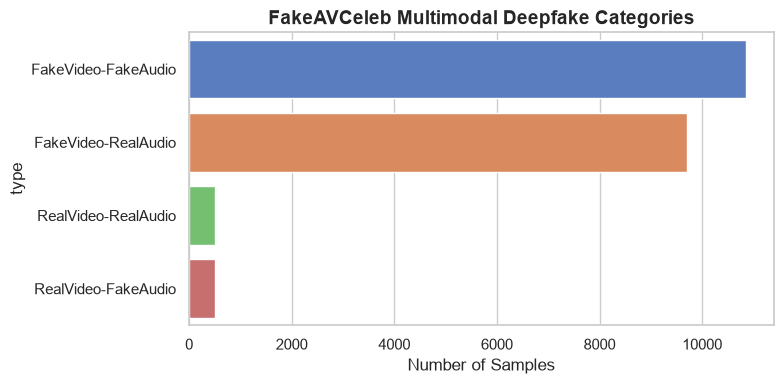

In [4]:
if 'df_meta' in locals():
    type_counts = df_meta['type'].value_counts()
    print("Cross-modal tampering breakdown:")
    print(type_counts)

    plt.figure(figsize=(8, 4))
    sns.barplot(x=type_counts.values, y=type_counts.index, hue=type_counts.index, legend=False)
    plt.title("FakeAVCeleb Multimodal Deepfake Categories", fontsize=14, fontweight="bold")
    plt.xlabel("Number of Samples")
    plt.tight_layout()
    plt.show()


## 4. Handling Missing & Corrupted Files
During data cleaning, integrity decoding was executed:
- Images decoded via PIL (`Image.verify()`)
- Videos opened via OpenCV (`cv2.VideoCapture` + `cap.read()`)
- Audio tracks verified via MP4 atom inspection (`b'soun'`)

Corrupted/unreadable files are isolated in `reports/corrupted_files.txt` and marked `is_valid = False` in the manifest.


In [5]:
if CORRUPT_LOG.exists():
    with open(CORRUPT_LOG, "r", encoding="utf-8") as f:
        lines = [line.strip() for line in f.readlines() if line.strip() and not line.startswith("#")]
    
    print(f"Total Corrupted / Incompatible Entries Detected: {len(lines)}")
    print("\nSample detected errors:")
    for l in lines[:5]:
        print(f"  • {l}")


Total Corrupted / Incompatible Entries Detected: 106

Sample detected errors:
  • [AUDIO] D:\deepfake_college_project\Deepfake-Analysis\dataset\raw\videos\audio_dataset.zio\FakeAVCeleb_v1.2\FakeAVCeleb_v1.2\FakeVideo-FakeAudio\African\men\id02268\00036_id00076_wavtolip.mp4 -> No audio atom ('soun') found in MP4 header
  • [AUDIO] D:\deepfake_college_project\Deepfake-Analysis\dataset\raw\videos\audio_dataset.zio\FakeAVCeleb_v1.2\FakeAVCeleb_v1.2\FakeVideo-FakeAudio\African\women\id00829\00271_id03747_wavtolip.mp4 -> No audio atom ('soun') found in MP4 header
  • [AUDIO] D:\deepfake_college_project\Deepfake-Analysis\dataset\raw\videos\audio_dataset.zio\FakeAVCeleb_v1.2\FakeAVCeleb_v1.2\FakeVideo-FakeAudio\Asian (East)\men\id01215\00001_0_id06152_wavtolip.mp4 -> No audio atom ('soun') found in MP4 header
  • [AUDIO] D:\deepfake_college_project\Deepfake-Analysis\dataset\raw\videos\audio_dataset.zio\FakeAVCeleb_v1.2\FakeAVCeleb_v1.2\FakeVideo-FakeAudio\Asian (East)\men\id01215\00001_0_id062

## 5. Ingesting & Analyzing the Dataset Manifest
The master manifest (`dataset_manifest.csv`) links all valid files to their exact modality, label, and stratified split.


In [6]:
df_manifest = pd.read_csv(MANIFEST_PATH)
print("Manifest Shape:", df_manifest.shape)
display(df_manifest.head(5))


Manifest Shape: (179137, 5)


,filepath,modality,label,is_valid,split
0,D:\deepfake_college_project\Deepfake-Analysis\...,image,Fake,True,train
1,D:\deepfake_college_project\Deepfake-Analysis\...,image,Fake,True,train
2,D:\deepfake_college_project\Deepfake-Analysis\...,image,Fake,True,train
3,D:\deepfake_college_project\Deepfake-Analysis\...,image,Fake,True,train
4,D:\deepfake_college_project\Deepfake-Analysis\...,image,Fake,True,train


### 5.1 Verification of Data Splits (Train, Validation, Test)
We use a stratified 70% Train / 15% Validation / 15% Test split to avoid bias.


In [7]:
split_summary = df_manifest[df_manifest['is_valid'] == True].groupby(['modality', 'split', 'label']).size().unstack(fill_value=0)
split_summary['Total'] = split_summary.sum(axis=1)
split_summary


label                 Fake  Real  Total
modality split                         
audio    test         1695  1524   3219
         train        7907  7110  15017
         validation   1694  1524   3218
image    test        19738   150  19888
         train       92110   700  92810
         validation  19738   150  19888
video    test         3545   204   3749
         train       16539   954  17493
         validation   3544   205   3749

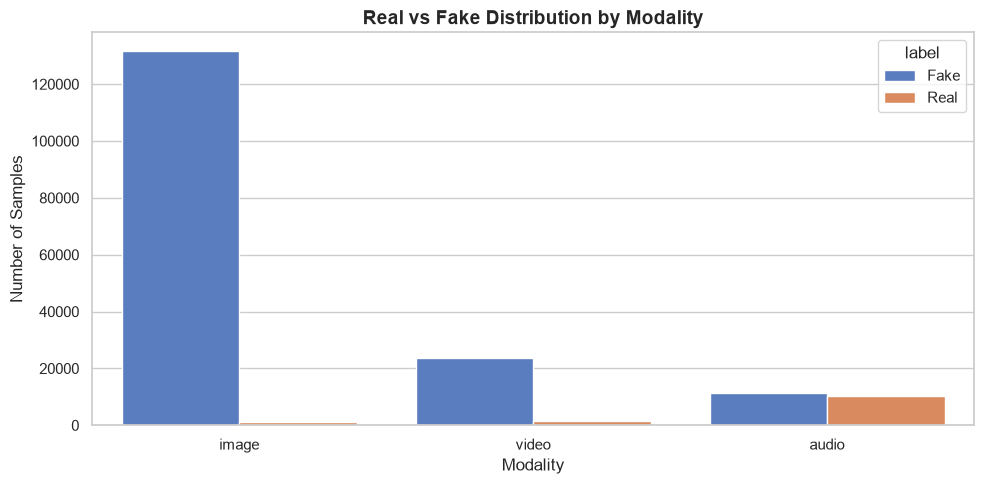

In [8]:
# Visualization of class distribution across modalities
plt.figure(figsize=(10, 5))
manifest_valid = df_manifest[df_manifest['is_valid'] == True]
sns.countplot(data=manifest_valid, x='modality', hue='label')
plt.title("Real vs Fake Distribution by Modality", fontsize=14, fontweight="bold")
plt.xlabel("Modality")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


## 6. Summary for Presentation
1. **Raw Dataset:** Over 179,000 files audited across images, video, and audio.
2. **Quality Control:** 106 corrupted / audio-less files isolated in `reports/corrupted_files.txt`.
3. **Reproducibility:** A persistent master manifest (`reports/dataset_manifest.csv`) indexes all files with deterministic train/val/test splits.
4. **Physical Demo Folders:** Clean balanced splits populated in `dataset/train/` and `dataset/test/` for model training and evaluation.
